The three ODE solvers which will be used are Runge-Kutta 45 (RK45) which is a standard explicit solver, Radau, which is an implicit Runge-Kutta solver, and LSODA, which is an adaptive solver which in addition to having adaptive timesteps also switches between the non-stiff Adams method and the stiff BDF method depending on how fast the stiffness it detects.

Solver time:  0.006475400005001575 s
Number of time steps taken:  1000
Accuracy: Idk
nfev/timesteps:  0.134


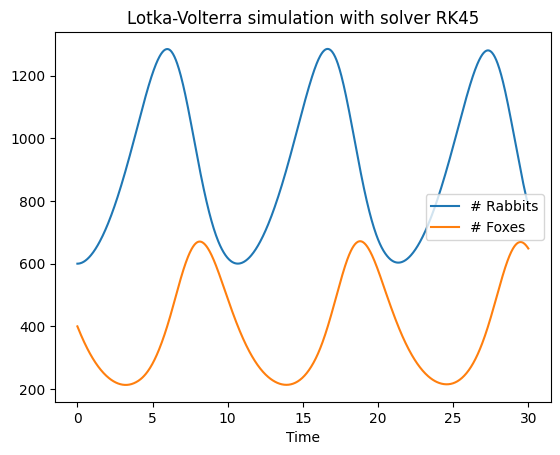

Solver time:  0.01922069996362552 s
Number of time steps taken:  1000
Accuracy: Idk
nfev/timesteps:  0.363


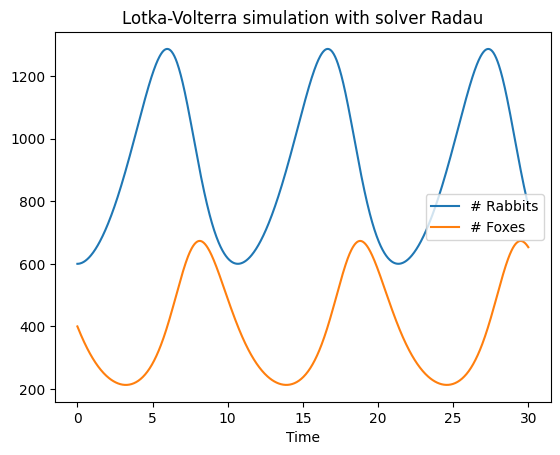

Solver time:  0.003552999987732619 s

Number of time steps taken:  1000
Accuracy: Idk
nfev/timesteps:  0.135


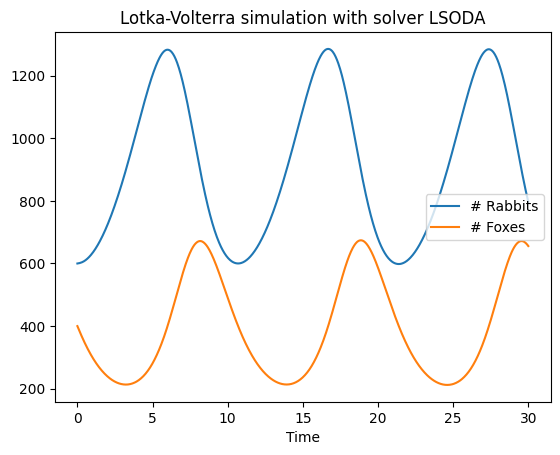

Solver  Runtime [s]  Steps  Error  nfev/step
  RK45     0.006475   1000      0      0.134
 Radau     0.019221   1000      0      0.363
 LSODA     0.003553   1000      0      0.135


In [ ]:
import time

from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp 

runtimes = []
nsteps = []
errors = []
nfevOverSteps = []


# Lotka-Volterra
def lotka_volterra(t,y,a,b,c,d):
    R,F = y

    dRdt = a*R-b*F*R
    dFdt = c*R*F-d*F

    return [dRdt, dFdt]

a = 0.4
b = 0.001
c = 0.001
d = 0.9

# Initial conditions
y0 = [600, 400]

# Time interval
t = [0, 30]

# RK45
t_eval = np.linspace(t[0],t[1],1000)
tStart = time.perf_counter() 
sol = solve_ivp(
    fun=lotka_volterra,
    t_span=t,
    y0=y0,
    method='RK45',
    args=(a,b,c,d),
    t_eval=t_eval
)
tEnd = time.perf_counter()
tSolv_RK45 = tEnd-tStart
steps_RK45 =  len(sol.t)
error_RK45 = 0 # IDK how to interpret
nfevOverSteps_RK45 = sol.nfev/len(sol.t)
print("Solver time: ",tSolv_RK45, "s")
print("Number of time steps taken: ", len(sol.t))
print("Accuracy: Idk")
print("nfev/timesteps: ",sol.nfev/len(sol.t))

plt.figure()
plt.title('Lotka-Volterra simulation with solver RK45')
plt.plot(sol.t, sol.y[0,:],label='# Rabbits')
plt.plot(sol.t, sol.y[1,:],label='# Foxes')
plt.xlabel('Time')
plt.legend()
plt.show()


# Radau
tStart = time.perf_counter() 
sol = solve_ivp(
    fun=lotka_volterra,
    t_span=t,
    y0=y0,
    method='Radau',
    args=(a,b,c,d),
    t_eval=t_eval
)
tEnd = time.perf_counter()
tSolv_Radau = tEnd-tStart
steps_Radau =  len(sol.t)
error_Radau = 0 # IDK how to interpret
nfevOverSteps_Radau = sol.nfev/len(sol.t)
print("Solver time: ",tSolv_Radau, "s")
print("Number of time steps taken: ", len(sol.t))
print("Accuracy: Idk")
print("nfev/timesteps: ",sol.nfev/len(sol.t))

plt.figure()
plt.title('Lotka-Volterra simulation with solver Radau')
plt.plot(sol.t, sol.y[0,:],label='# Rabbits')
plt.plot(sol.t, sol.y[1,:],label='# Foxes')
plt.xlabel('Time')
plt.legend()
plt.show()


# LSODA
tStart = time.perf_counter() 
sol = solve_ivp(
    fun=lotka_volterra,
    t_span=t,
    y0=y0,
    method='LSODA',
    args=(a,b,c,d),
    t_eval=t_eval
)
tEnd = time.perf_counter()
tSolv_LSODA = tEnd-tStart
steps_LSODA =  len(sol.t)
error_LSODA = 0 # IDK how to interpret
nfevOverSteps_LSODA = sol.nfev/len(sol.t)
print("Solver time: ",tSolv_LSODA, "s\n")
print("Number of time steps taken: ", len(sol.t))
print("Accuracy: Idk")
print("nfev/timesteps: ",sol.nfev/len(sol.t))

plt.figure()
plt.title('Lotka-Volterra simulation with solver LSODA')
plt.plot(sol.t, sol.y[0,:],label='# Rabbits')
plt.plot(sol.t, sol.y[1,:],label='# Foxes')
plt.xlabel('Time')
plt.legend()
plt.show()


# Make table with results (TODO: Make it automatic)
data = {
    "Solver": ["RK45", "Radau", "LSODA"],
    "Runtime [s]": [tSolv_RK45, tSolv_Radau, tSolv_LSODA],
    "Steps": [steps_RK45, steps_Radau, steps_LSODA],
    "Error": [error_RK45, error_Radau, error_LSODA],
    "nfev/step": [nfevOverSteps_RK45, nfevOverSteps_Radau, nfevOverSteps_LSODA]
}

df = pd.DataFrame(data)

print(df.to_string(index=False))

RK45 and LSODA seem to be similar in speed for and # of function evaluations per step. Radau slower and makes more calculations per step.

Solver time:  12.347596500010695 s
Number of time steps taken:  1000
Accuracy: Idk
nfev/timesteps:  1166.336


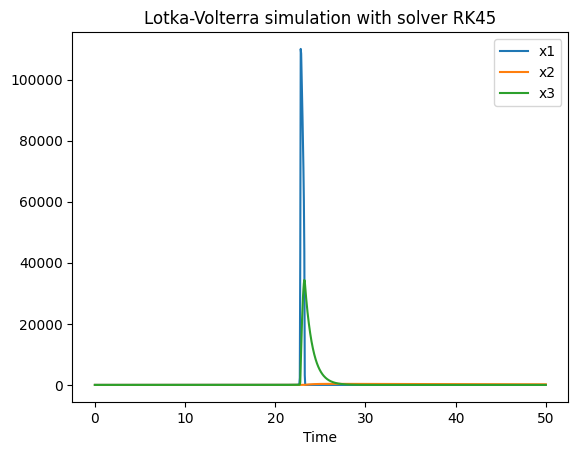

In [ ]:
def Belousov_Zhabotinsky(t, y, alpha, beta, gamma):
    x1,x2,x3 = y

    dx1dt = alpha*(x2+x1*(1-beta*x1-x2))
    dx2dt = 1/alpha*(x3-(1+x1)*x2)
    dx3dt = gamma*(x1-x3)

    return [dx1dt, dx2dt, dx3dt]

# Time interval
t = [0, 10]

# Initial conditions
y0 = [1, 2, 3]

# Constants
alpha = 77.27
beta = 8.375*10**-6
gamma = 1.161

t_eval = np.linspace(t[0], t[1], 1000)

tStart = time.perf_counter()
sol = solve_ivp(
    fun = Belousov_Zhabotinsky,
    t_span = t,
    y0 = y0,
    t_eval = t_eval,
    args=(alpha, beta, gamma),
    method="RK45"
)
tEnd = time.perf_counter()

tSolv_RK45 = tEnd-tStart
steps_RK45 =  len(sol.t)
error_RK45 = 0 # IDK how to interpret
nfevOverSteps_RK45 = sol.nfev/len(sol.t)
print("Solver time: ",tSolv_RK45, "s")
print("Number of time steps taken: ", len(sol.t))
print("Accuracy: Idk")
print("nfev/timesteps: ",sol.nfev/len(sol.t))

plt.figure()
plt.title('Lotka-Volterra simulation with solver RK45')
plt.plot(sol.t, sol.y[0,:],label='x1')
plt.plot(sol.t, sol.y[1,:],label='x2')
plt.plot(sol.t, sol.y[2,:],label='x3')
plt.xlabel('Time')
plt.legend()
plt.show()